<a href="https://colab.research.google.com/github/mavi02/Data_Viz/blob/main/ghg_analysis_week12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GHGRP United States Emissions Analytics (2010-2023)

## Complete Exploratory Data Analysis

This notebook provides a comprehensive analysis of the [EPA Greenhouse Gas Reporting Program (GHGRP) data from 2010 to 2023](http://epa.gov/ghgreporting/data-sets).

**Dataset**: Direct emitters from all reporting facilities across the United States.

**Analysis Sections**:
1. Dataset Structure + Trends
2. EDA and Insights
3. Visualizations



Greenhouse gas emissions are the release of gases into the atmosphere that trap heat and warm the planet through the natural greenhouse effect. While a baseline amount of these gases keeps Earth habitable, excess emissions from human activities act like a thick blanket, driving global warming and climate change.

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Load the cleaned dataset
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions")

df

,Summary data collected by the Greenhouse Gas Reporting Program,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,This data was reported to EPA by facilities as...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,All emissions data is presented in units of me...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Loca...,2019 Total reported direct emissions from Loca...,2018 Total reported direct emissions from Loca...,2017 Total reported direct emissions from Loca...,2016 Total reported direct emissions from Loca...,2015 Total reported direct emissions from Loca...,2014 Total reported direct emissions from Loca...,2013 Total reported direct emissions from Loca...,2012 Total reported direct emissions from Loca...,2011 Total reported direct emissions from Loca...
3,1008026,110071160130,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.69045,...,74939.996,74762.846,99558.146,74961.1,73739.346,105051.594,75801.6,75662.2,75480.25,73414.44
4,1004034,110071160131,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.55,14674.95,13714.75,13668.5,13556.8,13459.2,13412.6,13353.6,13736.25,13271.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206,1003558,110071160538,Waterville Gas & Oil Company,OH,Waterville,OH,43566,700 Farnsworth Rd.,LUCAS COUNTY,41.49916,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
207,1011115,110010642073,"West Texas Gas Utility, LLC",TX,Midland,TX,79705,303 Veterans Airpark Ln. Ste 5000,MIDLAND COUNTY,31.99906,...,31068.65,31950.75,32660.8,33870.3,33632,35567.8,34701.35,35376.5,35376.5,35376.5
208,1002025,110071161924,Wisconsin Power & Light Gas Distribution,WI,Madison,WI,53718,4902 North Biltmore Lane,DANE COUNTY,43.15217,...,21372.8,21428.4,20268.65,19805,19571.7,19264.2,17636.5,18285.1,18021.1,17562.298
209,1002250,110071160885,Wisconsin Public Service Corporation,WI,Green Bay,WI,54307,700 North Adams,BROWN COUNTY,44.518347,...,39796.998,40010.548,38662.8,37547.798,36968.098,35729.348,35367.198,35362.198,35333.698,34779.498


---

# PART 1: Dataset Structure + Trends

## 1.1 Dataset Structure



In [ ]:
# Reload the dataset skipping the first 3 lines of metadata to get the correct column headers
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions", skiprows=3)


In [ ]:
df.head()

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
0,1008026,1.100712e+11,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.690450,...,74939.996,74762.846,99558.146,74961.100,73739.346,105051.594,75801.60,75662.2,75480.25,73414.44
1,1004034,1.100712e+11,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.550,14674.950,13714.750,13668.500,13556.800,13459.200,13412.60,13353.6,13736.25,13271.75
2,1004975,1.100712e+11,Arkansas Oklahoma Gas Corp (AR),AR,Fort Smith,AR,72903,5030 South S Street,SEBASTIAN COUNTY,35.363559,...,NaN,NaN,NaN,8961.200,9771.050,11131.700,10870.50,10821.8,11025.50,11509.60
3,1006481,NaN,Arkansas Oklahoma Gas Corp (OK),OK,Fort Smith,AR,72903,5030 South S Street,NaN,35.363530,...,NaN,NaN,NaN,2983.450,2977.350,3220.500,2447.55,3111.7,3129.45,3426.50
4,1007872,1.100712e+11,Atlanta Gas Light Company,GA,Atlanta,GA,30309,Ten Peachtree Place,FULTON COUNTY,33.797114,...,165161.150,154525.296,156542.840,154795.438,151902.050,160923.894,155671.85,155513.8,191483.40,217658.90


In [ ]:
# Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [ ]:
# Statistical summary
df.describe()



,Facility Id,FRS Id,Reported Zip Code,Reported Latitude,Reported Longitude,Primary NAICS Code,2023 Total reported direct emissions from Local Distribution Companies,2022 Total reported direct emissions from Local Distribution Companies,2021 Total reported direct emissions from Local Distribution Companies,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
count,2.080000e+02,1.930000e+02,208.000000,208.000000,208.000000,208.000000,1.570000e+02,1.610000e+02,1.670000e+02,1.660000e+02,1.650000e+02,1.640000e+02,1.710000e+02,1.710000e+02,1.770000e+02,1.810000e+02,1.760000e+02,1.830000e+02,1.830000e+02
mean,1.005024e+06,1.100665e+11,47777.802885,38.524461,-89.849182,227121.331731,7.258495e+04,7.292821e+04,7.244788e+04,7.441292e+04,7.592974e+04,7.878849e+04,7.821742e+04,8.199183e+04,8.225036e+04,8.161244e+04,8.614471e+04,8.422047e+04,8.561719e+04
std,2.663140e+03,1.210254e+07,26862.431274,4.604929,13.028731,54862.838190,1.311826e+05,1.298880e+05,1.311463e+05,1.367190e+05,1.395165e+05,1.428410e+05,1.450002e+05,1.550096e+05,1.562151e+05,1.499857e+05,1.564369e+05,1.561862e+05,1.606826e+05
min,1.000011e+06,1.100008e+11,2090.000000,26.710000,-122.672440,221121.000000,3.600000e+02,3.600000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.003016e+06,1.100712e+11,26109.500000,35.293171,-96.816130,221210.000000,7.908500e+03,8.154200e+03,6.984450e+03,7.227513e+03,7.164350e+03,7.414025e+03,6.280300e+03,6.851950e+03,6.761350e+03,6.323600e+03,6.849762e+03,6.222275e+03,6.228275e+03
50%,1.004856e+06,1.100712e+11,47276.500000,39.213429,-87.962713,221210.000000,3.354725e+04,3.389830e+04,3.229765e+04,3.240500e+04,3.195075e+04,3.159775e+04,3.265105e+04,3.331435e+04,3.274490e+04,3.380995e+04,3.494277e+04,3.571625e+04,3.477950e+04
75%,1.006615e+06,1.100712e+11,71279.500000,41.630795,-80.049390,221210.000000,7.872180e+04,8.103000e+04,7.815057e+04,8.275570e+04,8.489845e+04,9.037188e+04,8.096192e+04,8.368245e+04,8.576629e+04,8.872980e+04,9.847775e+04,9.818050e+04,9.620910e+04
max,1.014465e+06,1.100712e+11,99336.000000,47.660000,-68.805810,921120.000000,1.287219e+06,1.251821e+06,1.255797e+06,1.309065e+06,1.307009e+06,1.313835e+06,1.318935e+06,1.330007e+06,1.331063e+06,1.333550e+06,1.357409e+06,1.385094e+06,1.350350e+06


In [ ]:
# Calculate means for numeric columns only, then fill missing values
df = df.fillna(df.mean(numeric_only=True))



In [ ]:
# Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  208 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [ ]:
# Convert entire dataframe to numpy array
ghg_array = df.to_numpy()

# emissions columns are at indices 13 through 25
emissions_only = ghg_array[:, 13:].astype(float)

# Sum down columns ignoring missing values
column_sums = np.sum(emissions_only, axis=0)
print(column_sums)
column_sums_LDC = np.flip(column_sums)
print(column_sums_LDC)

[15097669.60264968 15169067.20198758 15069159.34639521 15477887.22968675
 15793386.25532121 16388006.10770731 16269222.85155556 17054300.99031579
 17108074.81419209 16975388.07160221 17918099.25454546 17517858.32148634
 17808374.54933333]
[17808374.54933333 17517858.32148634 17918099.25454546 16975388.07160221
 17108074.81419209 17054300.99031579 16269222.85155556 16388006.10770731
 15793386.25532121 15477887.22968675 15069159.34639521 15169067.20198758
 15097669.60264968]


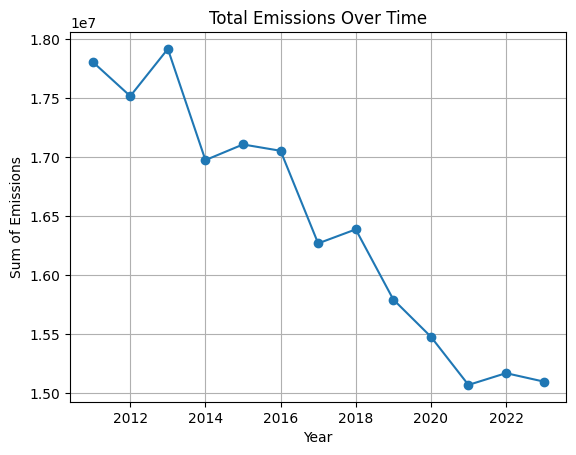

In [ ]:
# Plot line chart

years = np.array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
plt.plot(years, column_sums_LDC, marker="o")
plt.title("Total Emissions Over Time")
plt.xlabel("Year")
plt.ylabel("Sum of Emissions")
plt.grid(True)
plt.show()

0      1.054888e+06
1      1.827507e+05
2      5.211835e+05
3      4.683887e+05
4      2.217845e+06
           ...     
203    8.840537e+05
204    4.309091e+05
205    2.617755e+05
206    4.895121e+05
207    8.091863e+05
Name: Total_Emissions_All_Years, Length: 208, dtype: float64
State where Emissions Occur
AL    3.738157e+06
AR    2.917096e+06
AZ    1.456982e+06
CA    2.230522e+07
CO    5.107969e+06
CT    2.887288e+06
DC    9.251512e+05
DE    5.594922e+05
FL    3.181173e+06
GA    3.101236e+06
IA    1.315314e+06
ID    5.195352e+05
IL    6.301472e+06
IN    3.979728e+06
KS    2.200683e+06
KY    1.669157e+06
LA    1.963343e+06
MA    9.062793e+06
MD    4.727669e+06
ME    1.930571e+06
MI    9.239347e+06
MN    3.445111e+06
MO    3.965025e+06
MS    9.320999e+05
MT    1.196188e+06
NC    3.156772e+06
ND    1.729626e+06
NE    2.764632e+06
NH    9.687832e+05
NJ    1.115729e+07
NM    9.286527e+05
NV    5.446316e+05
NY    1.691186e+07
OH    1.541602e+07
OK    2.869226e+06
OR    2.350436e+06
PA    1

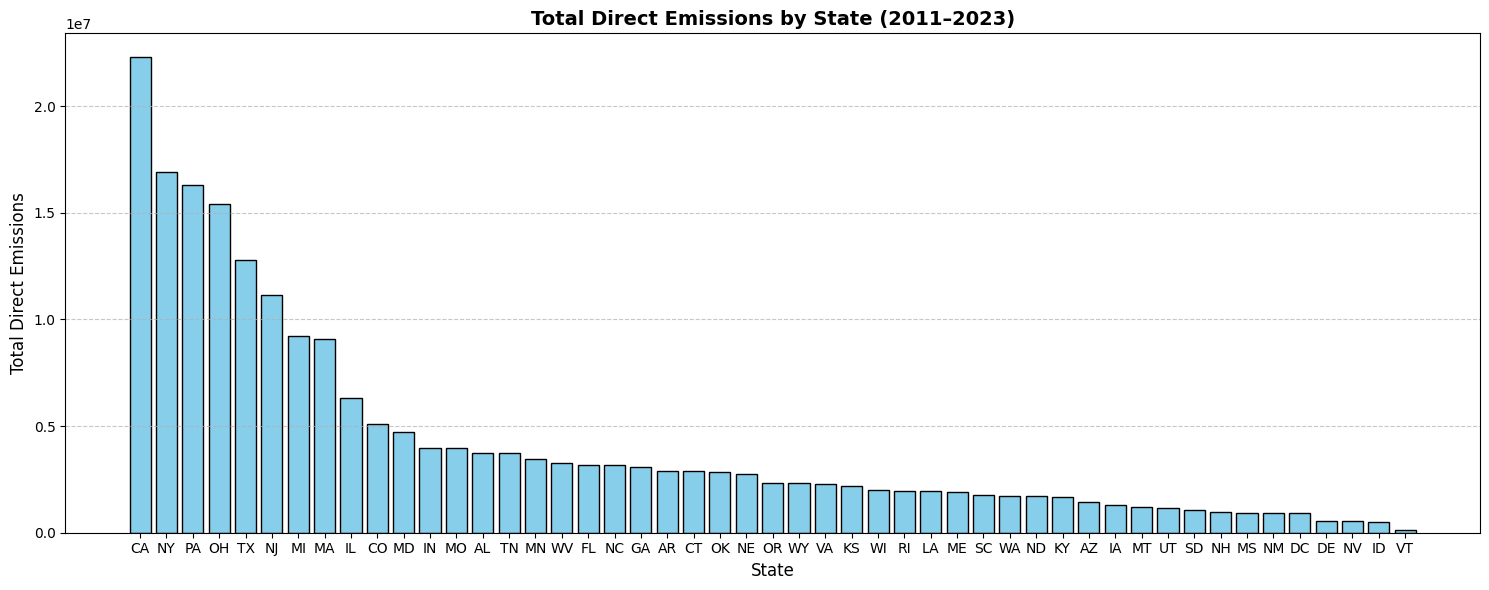

In [ ]:

# 1. Define all emission columns
cols = [
    "2011 Total reported direct emissions from Local Distribution Companies",
    "2012 Total reported direct emissions from Local Distribution Companies",
    "2013 Total reported direct emissions from Local Distribution Companies",
    "2014 Total reported direct emissions from Local Distribution Companies",
    "2015 Total reported direct emissions from Local Distribution Companies",
    "2016 Total reported direct emissions from Local Distribution Companies",
    "2017 Total reported direct emissions from Local Distribution Companies",
    "2018 Total reported direct emissions from Local Distribution Companies",
    "2019 Total reported direct emissions from Local Distribution Companies",
    "2020 Total reported direct emissions from Local Distribution Companies",
    "2021 Total reported direct emissions from Local Distribution Companies",
    "2022 Total reported direct emissions from Local Distribution Companies",
    "2023 Total reported direct emissions from Local Distribution Companies",
]

# 2. Add a new column with total emissions across all years for each facility
df["Total_Emissions_All_Years"] = df[cols].sum(axis=1)
print(df["Total_Emissions_All_Years"])

# 3. Group by State and sum total emissions per state
state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"]


state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum()
print(state_emissions)

state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum().reset_index()
print(state_emissions)

# Sort by emissions in descending order for better visualization
state_emissions = state_emissions.sort_values(by="Total_Emissions_All_Years", ascending=False)

# # 4. Extract data to NumPy arrays for plotting
states = state_emissions["State where Emissions Occur"]
emissions_by_state = state_emissions["Total_Emissions_All_Years"]

# 5. Create Bar Chart
plt.figure(figsize=(15, 6))
plt.bar(states, emissions_by_state, color="skyblue", edgecolor="black")

plt.title("Total Direct Emissions by State (2011–2023)", fontsize=14, fontweight="bold")
plt.xlabel("State", fontsize=12)
plt.ylabel("Total Direct Emissions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)


plt.tight_layout()
plt.show()

Electricity transmission lines and local distribution lines are the two main stages of the power grid that move energy from power plants to your home, much like comparing a major interstate highway to local neighborhood streets.

• Transmission Lines: Carry bulk, high-voltage electricity over long distances from power plants to regional substations. They form the backbone of the national electrical grid.
• Distribution Lines: Take the lowered-voltage electricity from local substations and deliver it directly to homes, schools, and businesses.

In [ ]:
# Load the cleaned dataset
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="Transmission Pipelines", skiprows=3)

df

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,Primary NAICS Code,Latest Reported Industry Type (subparts),2023 Total reported direct emissions from Transmission Pipelines,2022 Total reported direct emissions from Transmission Pipelines,2021 Total reported direct emissions from Transmission Pipelines,2020 Total reported direct emissions from Transmission Pipelines,2019 Total reported direct emissions from Transmission Pipelines,2018 Total reported direct emissions from Transmission Pipelines,2017 Total reported direct emissions from Transmission Pipelines,2016 Total reported direct emissions from Transmission Pipelines
0,1014613,1.100714e+11,Acadian Gas Pipeline System,Louisiana,Houston,TX,77002,1100 Louisiana Street,HARRIS COUNTY,29.757726,...,486210,W-TRANS,40678.788049,32176.604762,NaN,NaN,NaN,NaN,NaN,NaN
1,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,Connecticut,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1541.800000,1036.70,7735.400000,717.300000,10773.15,1264.25
2,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,Massachusetts,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1815.350000,337.40,3347.650000,23.000000,264.55,7515.45
3,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,New Jersey,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1294.500000,9.75,465.750000,1520.800000,19.25,NaN
4,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,New York,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,612.950000,39.50,4692.150000,7092.200000,1551.05,24960.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,Montana,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,2112.975240,2624.50,3916.493950,704.891554,NaN,NaN
236,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,North Dakota,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,3265.621728,2276.85,4419.993522,17891.074516,NaN,NaN
237,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,South Dakota,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,852.623118,3939.75,NaN,7658.525978,NaN,NaN
238,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,Wyoming,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,NaN,2407.55,1938.657154,316.345617,NaN,NaN
